# Track C: next-day extreme rainfall (simulated data)

**Research question.** If validation mimics the test set (later years, stations never seen), how much does heavy-rain skill drop compared with a random split, and which single design choices (physical features, station identity, recency weighting, class weighting) help under that shift?

**Protocol (fixed before any modelling).**
- **Tuning folds:** validate on 2015, 2016, 2017, 2018, each trained on earlier years only, with 4 stations held out of training per fold. Every choice below is made here.
- **Final holdout:** validate on 2019-2020 (train on 2010-2018, 4 stations held out). Scored **once**, after all choices are frozen.
- **Test file:** read only in the last section, to predict.
- **Metric:** average precision (AP). Score = mean of AP on seen stations and AP on held-out stations.
- **Adoption rule** for any experiment: adopt a change only if it beats the base in at least 3 of 4 tuning folds *and* on average.

Everything is classical ML. The data are **simulated**; conclusions are about the simulated system, not real climate.

## 0. Setup

In [1]:
import os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, lightgbm as lgb
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score as ap, roc_auc_score, precision_recall_curve

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 170, "display.precision", 4)
print("pandas", pd.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__, "| lightgbm", lgb.__version__)

RESULTS = []  # every reported run is appended here and saved to experimental_results.csv at the end

def log(stage, experiment, run, r, desc="", **extra):
    """Record one run: r is a per-fold table from table()."""
    RESULTS.append(dict(stage=stage, experiment=experiment, run=run, description=desc,
                        score=r.score.mean(), score_std=r.score.std(), ap_seen=r.seen.mean(),
                        ap_unseen=r.unseen.mean(), roc_auc=r.auc.mean(), n_folds=len(r), **extra))

pandas 3.1.0 | numpy 2.5.4 | sklearn 1.9.1 | lightgbm 4.7.0


In [2]:
SLUG = "iml2026-track-c-simulated-extreme-rain"
DATA = next(Path(c) for c in [os.environ.get("IML_DATA_DIR", ""), f"/kaggle/input/{SLUG}",
                              "iml-2026-track-c-extreme-rainfall", "data"]
            if c and (Path(c) / "train.csv").exists())
TARGET, LEAK = "heavy_rain_tomorrow", ["rain_tomorrow_mm"]   # rain_tomorrow_mm defines the label: never a feature
tr = pd.read_csv(DATA / "train.csv", parse_dates=["date"])    # test.csv is NOT read until section 9
print(DATA, tr.shape)

iml-2026-track-c-extreme-rainfall (64288, 23)


## 1. Data audit

positive rate 3.296% | stations 16 | years 2010-2020
columns with missing values:
 {'rh_1500_pct': 0.033, 'pressure_change_24h_hpa': 0.0, 'precipitable_water_mm': 0.022, 'instability_index_jkg': 0.032, 'wind_speed_ms': 0.025}
next-day rain_today == rain_tomorrow (rows with a next day): 1.0
date gaps within stations: 0


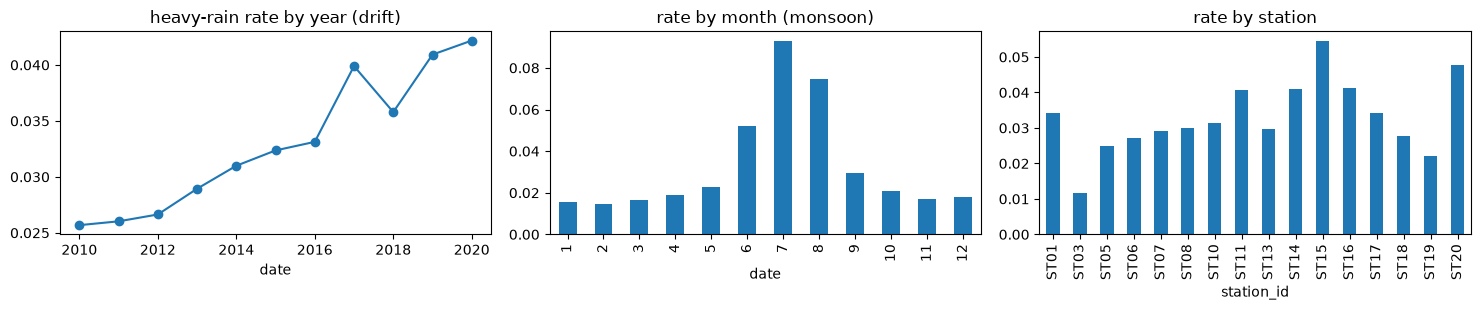

In [3]:
print(f"positive rate {tr[TARGET].mean():.3%} | stations {tr.station_id.nunique()} | years {tr.date.dt.year.min()}-{tr.date.dt.year.max()}")
miss = tr.isna().mean(); print("columns with missing values:\n", miss[miss > 0].round(3).to_dict())

# Leak trap: the NEXT day's rain_today_mm equals THIS row's rain_tomorrow_mm, so lags may only look backward.
s = tr.sort_values(["station_id", "date"])
nxt = s.groupby("station_id").rain_today_mm.shift(-1)
print("next-day rain_today == rain_tomorrow (rows with a next day):", (nxt == s.rain_tomorrow_mm)[nxt.notna()].mean())
print("date gaps within stations:", int((s.groupby("station_id").date.diff().dt.days.dropna() != 1).sum()))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
tr.groupby(tr.date.dt.year)[TARGET].mean().plot(ax=ax[0], marker="o", title="heavy-rain rate by year (drift)")
tr.groupby(tr.date.dt.month)[TARGET].mean().plot.bar(ax=ax[1], title="rate by month (monsoon)")
tr.groupby("station_id")[TARGET].mean().plot.bar(ax=ax[2], title="rate by station")
plt.tight_layout(); plt.show()

## 2. Features
Built per station in date order, using **only today and earlier days**. The spatial groups use other stations' *same-day* readings only (all known at prediction time). Features are organised in named groups so that each experiment can change exactly one group.

| group | content |
|---|---|
| `static` | latitude, longitude, elevation, distance to coast |
| `weather` | today's raw measurements + wind-sector one-hot |
| `calendar` | day-of-year sin/cos (monsoon seasonality) |
| `physical` | dew-point depression, diurnal range, 0900->1500 humidity drop |
| `history` | lag 1-2, 1-day change, 3/7-day means of key variables, 7-day rain |
| `anomaly` | today minus the station's own trailing-365-day mean (ends yesterday), to cancel drift/recalibration |
| `missing` | missing-value indicators for the columns with outages |
| `station` | station-id one-hot (only used in experiment E3) |
| `regional` | same-day mean of all OTHER stations (pressure change, RH, PW, instability, rain, MSLP, share with heavy rain today) |
| `neighbour` | same variables, inverse-distance mean of the 3 nearest stations (a disturbance next door today may arrive tomorrow) |
| `upwind` | same variables, inverse-distance mean of stations lying in the direction the wind comes from (within 45 deg) |

In [4]:
STATIC = ["latitude", "longitude", "elevation_m", "distance_to_coast_km"]
WEATHER = ["tmax_c", "tmin_c", "dewpoint_c", "rh_0900_pct", "rh_1500_pct", "mslp_hpa", "pressure_change_24h_hpa",
           "precipitable_water_mm", "instability_index_jkg", "wind_speed_ms", "cloud_cover_okta",
           "rain_today_mm", "rain_last_3d_mm"]
HISTCOLS = ["precipitable_water_mm", "instability_index_jkg", "mslp_hpa", "rh_0900_pct", "rh_1500_pct", "dewpoint_c", "rain_today_mm"]
ANOMCOLS = ["precipitable_water_mm", "instability_index_jkg", "dewpoint_c", "tmax_c", "mslp_hpa"]
MISSCOLS = [c for c in WEATHER if tr[c].isna().mean() > 0.005]   # outage columns (ignores first-day NaNs of pressure change)
WINDS = sorted(tr.wind_dir_sector.dropna().unique())             # fixed category lists so train/test columns align
STATIONS = sorted(tr.station_id.unique())

SPATIAL_COLS = ["pressure_change_24h_hpa", "rh_1500_pct", "precipitable_water_mm", "instability_index_jkg",
                "rain_today_mm", "mslp_hpa", "heavy_today"]
K_NN = 3
WIND_FROM = {"N": 0, "NE": 45, "E": 90, "SE": 135, "S": 180, "SW": 225, "W": 270, "NW": 315}  # degrees the wind blows FROM
assert set(WINDS) <= set(WIND_FROM)

def spatial_features(df):
    """Same-day features from OTHER stations. Returns {group: DataFrame}: regional / neighbour / upwind."""
    d = df.assign(heavy_today=(df.rain_today_mm >= 64.5).astype(float))
    st = d.groupby("station_id")[["latitude", "longitude"]].first()
    la, lo = np.radians(st.latitude.values)[:, None], np.radians(st.longitude.values)[:, None]
    dist = 2 * 6371 * np.arcsin(np.sqrt(np.sin((la - la.T) / 2) ** 2 + np.cos(la) * np.cos(la.T) * np.sin((lo - lo.T) / 2) ** 2))
    np.fill_diagonal(dist, np.inf)                                   # a station is never its own neighbour
    bearing = np.degrees(np.arctan2(np.sin(lo.T - lo) * np.cos(la.T),
                                    np.cos(la) * np.sin(la.T) - np.sin(la) * np.cos(la.T) * np.cos(lo.T - lo))) % 360
    inv, n = 1 / dist, len(st)
    W_reg = 1.0 - np.eye(n)                                          # all others, equal weight
    W_nn = np.zeros((n, n))
    for i in range(n):
        near = np.argsort(dist[i])[:K_NN]; W_nn[i, near] = inv[i, near]
    W_up = {s: (np.abs((bearing - a + 180) % 360 - 180) <= 45) * inv for s, a in WIND_FROM.items()}   # cone toward where wind comes from
    sector = d.wind_dir_sector.values
    out = {"regional": {}, "neighbour": {}, "upwind": {}}
    for c in SPATIAL_COLS:
        wide = d.pivot(index="date", columns="station_id", values=c).reindex(columns=st.index)
        X, M = wide.fillna(0).values, wide.notna().values.astype(float)
        di, si = wide.index.get_indexer(d.date), st.index.get_indexer(d.station_id)
        def look(W):                                                  # weighted mean over available neighbours, per row
            num, den = X @ W.T, M @ W.T
            with np.errstate(invalid="ignore", divide="ignore"):
                return np.where(den > 0, num / den, np.nan)[di, si]
        out["regional"]["reg_" + c], out["neighbour"]["nn_" + c] = look(W_reg), look(W_nn)
        up = np.full(len(d), np.nan)
        for s in WIND_FROM:
            rows = sector == s; up[rows] = look(W_up[s])[rows]
        out["upwind"]["up_" + c] = up
    return {g: pd.DataFrame(v, index=df.index) for g, v in out.items()}

def build_features(df):
    """Return the sorted frame and a dict {group: feature DataFrame}. Backward-looking only."""
    df = df.sort_values(["station_id", "date"]).reset_index(drop=True)
    g = df.groupby("station_id", sort=False)
    G = {"static": df[STATIC].copy()}
    wind = pd.DataFrame({f"wind_{w}": (df.wind_dir_sector == w).astype(int) for w in WINDS})
    G["weather"] = pd.concat([df[WEATHER], wind], axis=1)
    doy = df.date.dt.day_of_year
    G["calendar"] = pd.DataFrame({"doy_sin": np.sin(2 * np.pi * doy / 365.25), "doy_cos": np.cos(2 * np.pi * doy / 365.25)})
    G["physical"] = pd.DataFrame({"dew_depr": df.tmax_c - df.dewpoint_c, "diurnal": df.tmax_c - df.tmin_c,
                                  "rh_drop": df.rh_0900_pct - df.rh_1500_pct})
    h = {}
    for c in HISTCOLS:
        h[c + "_lag1"], h[c + "_lag2"] = g[c].shift(1), g[c].shift(2)
        h[c + "_d1"] = df[c] - h[c + "_lag1"]
        h[c + "_m3"] = g[c].transform(lambda s: s.rolling(3, min_periods=1).mean())
        h[c + "_m7"] = g[c].transform(lambda s: s.rolling(7, min_periods=1).mean())
    h["rain_7d"] = g["rain_today_mm"].transform(lambda s: s.rolling(7, min_periods=1).sum())
    G["history"] = pd.DataFrame(h)
    G["anomaly"] = pd.DataFrame({"anom_" + c: df[c] - g[c].transform(lambda s: s.shift(1).rolling(365, min_periods=30).mean())
                                 for c in ANOMCOLS})
    G["missing"] = pd.DataFrame({"miss_" + c: df[c].isna().astype(int) for c in MISSCOLS})
    G["station"] = pd.DataFrame({"st_" + s: (df.station_id == s).astype(int) for s in STATIONS})
    G.update(spatial_features(df))
    return df, G

def fm(groups, G):
    """Stack feature groups into one matrix."""
    return pd.concat([G[k] for k in groups], axis=1)

trs, Gtr = build_features(tr)
ytr, yr = trs[TARGET].values, trs.date.dt.year.values
stn, month = trs.station_id.values, trs.date.dt.month.values
print({k: v.shape[1] for k, v in Gtr.items()}, "| missing-flag columns:", MISSCOLS)

{'static': 4, 'weather': 21, 'calendar': 2, 'physical': 3, 'history': 36, 'anomaly': 5, 'missing': 4, 'station': 16, 'regional': 7, 'neighbour': 7, 'upwind': 7} | missing-flag columns: ['rh_1500_pct', 'precipitable_water_mm', 'instability_index_jkg', 'wind_speed_ms']


**Leakage guard:** change every weather value from 2016 onward and rebuild. Features for dates before 2016 must not move at all, otherwise some feature looks ahead.

In [5]:
cutoff = pd.Timestamp("2016-01-01")
alt = tr.copy()
late = alt.date >= cutoff
alt[WEATHER] = alt[WEATHER].astype(float)
alt.loc[late, WEATHER] = alt.loc[late, WEATHER] * 1.7 + 3
_, G2 = build_features(alt)
early = (trs.date < cutoff).values
for k in Gtr:
    if k in ("static", "calendar", "station"): continue
    assert np.allclose(Gtr[k][early].values, G2[k][early].values, equal_nan=True), f"look-ahead in group {k}"
assert not any("tomorrow" in c for k in Gtr for c in Gtr[k].columns)
print("OK: no feature group changes when future data change; no target-derived columns.")

OK: no feature group changes when future data change; no target-derived columns.


## 3. Validation folds and evaluation harness
`DEV` = tuning folds. `HOLD` = final holdout, used once in section 8. In each fold, 4 stations are removed from training, so AP is reported separately on `seen` and `unseen` stations.

In [6]:
perm = np.random.RandomState(SEED).permutation(STATIONS)
GROUPS4 = [perm[4 * k:4 * k + 4] for k in range(4)]            # rotating blocks of held-out stations

def make_fold(name, val_years, held):
    is_held = np.isin(stn, held)
    return dict(name=name, tri=(yr < min(val_years)) & ~is_held, vai=np.isin(yr, val_years), held=is_held)

DEV = [make_fold(f"dev{Y}", [Y], GROUPS4[i]) for i, Y in enumerate([2015, 2016, 2017, 2018])]
HOLD = make_fold("holdout2019-20", [2019, 2020], GROUPS4[0])
for f in DEV + [HOLD]:
    print(f["name"], "train rows", f["tri"].sum(), "| val rows", f["vai"].sum(), "| val positives", ytr[f["vai"]].sum(),
          "| held-out stations", sorted(set(stn[f["held"]])))
print("constant-predictor AP = prevalence, per fold:", [round(ytr[f["vai"]].mean(), 4) for f in DEV + [HOLD]])

dev2015 train rows 21912 | val rows 5840 | val positives 189 | held-out stations ['ST01', 'ST03', 'ST08', 'ST19']
dev2016 train rows 26292 | val rows 5856 | val positives 194 | held-out stations ['ST13', 'ST14', 'ST16', 'ST18']
dev2017 train rows 30684 | val rows 5840 | val positives 233 | held-out stations ['ST05', 'ST07', 'ST11', 'ST20']
dev2018 train rows 35064 | val rows 5840 | val positives 209 | held-out stations ['ST06', 'ST10', 'ST15', 'ST17']
holdout2019-20 train rows 39444 | val rows 11696 | val positives 486 | held-out stations ['ST01', 'ST03', 'ST08', 'ST19']
constant-predictor AP = prevalence, per fold: [np.float64(0.0324), np.float64(0.0331), np.float64(0.0399), np.float64(0.0358), np.float64(0.0416)]


In [7]:
def safe_ap(y, p):  return ap(y, p) if len(y) and y.sum() > 0 else np.nan
def safe_auc(y, p): return roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan

def table(preds, folds):
    """Per-fold AP on seen / unseen stations (+ROC-AUC); score = mean(seen, unseen)."""
    rows = []
    for f in folds:
        p, y, h = preds[f["name"]], ytr[f["vai"]], f["held"][f["vai"]]
        rows.append(dict(fold=f["name"], seen=safe_ap(y[~h], p[~h]), unseen=safe_ap(y[h], p[h]), auc=safe_auc(y, p)))
    r = pd.DataFrame(rows).set_index("fold")
    r["score"] = r[["seen", "unseen"]].mean(axis=1)
    return r

def run(fit_pred, folds=DEV):
    preds = {f["name"]: fit_pred(f) for f in folds}
    return table(preds, folds), preds

def _score(m, X): return m.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X)

def sk(make_model, X, decay=None):
    """sklearn pipeline (imputer/scaler fitted inside each training fold). decay -> recency sample weights."""
    Xv = X.values
    def fp(f):
        tri = f["tri"]; m = make_model(); kw = {}
        if decay is not None: kw[m.steps[-1][0] + "__sample_weight"] = decay ** (yr[tri].max() - yr[tri])
        m.fit(Xv[tri], ytr[tri], **kw)
        return _score(m, Xv[f["vai"]])
    return fp

LGB_BASE = dict(learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0,
                verbose=-1, n_jobs=1, deterministic=True, force_row_wise=True)
def lgbm(X, decay=None, seeds=(SEED,), **params):
    Xv = X.values
    def fp(f):
        tri = f["tri"]; w = None if decay is None else decay ** (yr[tri].max() - yr[tri])
        ps = [lgb.LGBMClassifier(**{**LGB_BASE, **params}, random_state=s).fit(Xv[tri], ytr[tri], sample_weight=w)
              .predict_proba(Xv[f["vai"]])[:, 1] for s in seeds]
        return np.mean(ps, axis=0)
    return fp

def LR(C=1.0, cw=None):
    return lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                 LogisticRegression(C=C, class_weight=cw, max_iter=3000))

def compare(base, runs):
    """Paired per-fold comparison against base. adopt = better in >=3 of 4 folds AND on average."""
    rows = [dict(run="BASE", score=base.score.mean(), delta=0.0, folds_better="-", adopt="-")]
    for name, r in runs.items():
        d = r.score - base.score
        rows.append(dict(run=name, score=r.score.mean(), delta=d.mean(), folds_better=int((d > 0).sum()),
                         adopt=bool((d > 0).sum() >= 3 and d.mean() > 0)))
    return pd.DataFrame(rows).set_index("run")

## 4. Baselines (same protocol)
Trivial and climatology baselines, plus models taught in lectures: regularised logistic regression (default settings, standardised, the organiser-style reference), LDA, Gaussian Naive Bayes, linear SVM. All use the raw features (`static` + `weather`).
Climatology = training rate per station and calendar month; for unseen stations it falls back to the month-only rate.

In [8]:
RAW = ["static", "weather"]
Xraw = fm(RAW, Gtr)

def const_fp(f): return np.full(f["vai"].sum(), ytr[f["tri"]].mean())

def clim_fp(f):
    tri, vai = f["tri"], f["vai"]
    d = pd.DataFrame(dict(s=stn, m=month, y=ytr))[tri]
    by_sm, by_m = d.groupby(["s", "m"]).y.mean(), d.groupby("m").y.mean()
    p = by_sm.reindex(pd.MultiIndex.from_arrays([stn[vai], month[vai]])).values
    return np.where(np.isnan(p), by_m.reindex(month[vai]).values, p)

pipe = lambda clf: (lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), clf))
BASELINES = {
    "constant (prior)":        const_fp,
    "climatology (stn x mon)": clim_fp,
    "logistic reg (default)":  sk(LR(), Xraw),
    "LDA":                     sk(pipe(LinearDiscriminantAnalysis()), Xraw),
    "Gaussian NB":             sk(pipe(GaussianNB()), Xraw),
    "linear SVM":              sk(pipe(LinearSVC(dual="auto", max_iter=5000)), Xraw),
}
base_tab = {}
for name, fp in BASELINES.items():
    r, _ = run(fp); base_tab[name] = r; log("dev", "baselines", name, r, "raw features")
pd.DataFrame({k: dict(score=v.score.mean(), std=v.score.std(), seen=v.seen.mean(), unseen=v.unseen.mean(), auc=v.auc.mean())
              for k, v in base_tab.items()}).T

,score,std,seen,unseen,auc
constant (prior),0.0361,0.0062,0.0345,0.0376,0.5000
climatology (stn x mon),0.0809,0.0086,0.0803,0.0814,0.6899
logistic reg (default),0.2145,0.0403,0.2040,0.2250,0.8257
LDA,0.1984,0.0313,0.1890,0.2078,0.8217
Gaussian NB,0.1588,0.0244,0.1494,0.1681,0.7859
linear SVM,0.2065,0.0388,0.1965,0.2165,0.8211


## 5. Controlled experiments (tuning folds only)

### E1. Validation scheme
*Expectation:* a random split overstates skill (neighbouring days leak across the split); blocked-by-time is in between; the chronological + unseen-station scheme is lowest. The gap should be larger for a flexible model (LightGBM) than for LR.
All schemes score the same rows (2015-2018) and use only 2010-2018 data, so the holdout years stay untouched.

In [9]:
dev_rows = yr <= 2018
VAL_ROWS = np.where((yr >= 2015) & (yr <= 2018))[0]           # the SAME rows every scheme is scored on
def scheme_folds(kind):
    if kind == "random":     # shuffle validation rows into 5 folds; training keeps neighbouring days and the future
        sets = [VAL_ROWS[v] for _, v in StratifiedKFold(5, shuffle=True, random_state=SEED).split(VAL_ROWS, ytr[VAL_ROWS])]
    else:                    # blocked: leave one whole year out; training may include later years
        sets = [VAL_ROWS[yr[VAL_ROWS] == Y] for Y in range(2015, 2019)]
    out = []
    for k, v in enumerate(sets):
        vai = np.zeros(len(tr), bool); vai[v] = True
        out.append(dict(name=f"{kind}{k}", tri=dev_rows & ~vai, vai=vai, held=np.zeros(len(tr), bool)))
    return out

ALL = ["static", "weather", "calendar", "physical", "history", "anomaly", "missing"]
models = {"LR (raw)": sk(LR(), Xraw), "LightGBM (all feats)": lgbm(fm(ALL, Gtr), n_estimators=300, num_leaves=15, min_child_samples=100)}
rows = {}
for mname, fp in models.items():
    for kind, label in [("random", "random 5-fold"), ("blocked", "leave-one-year-out")]:
        r, _ = run(fp, scheme_folds(kind)); rows.setdefault(label, {})[mname] = r.seen.mean(); log("dev", "E1 validation scheme", f"{mname} | {label}", r)
    r, _ = run(fp); rows.setdefault("chronological, seen stations", {})[mname] = r.seen.mean()
    rows.setdefault("chronological, unseen stations", {})[mname] = r.unseen.mean(); log("dev", "E1 validation scheme", f"{mname} | chronological", r)
e1 = pd.DataFrame(rows).T; e1

,LR (raw),LightGBM (all feats)
random 5-fold,0.2128,0.2113
leave-one-year-out,0.2069,0.2096
"chronological, seen stations",0.2040,0.1967
"chronological, unseen stations",0.2250,0.2428


### E2. Feature groups
Base = LR on raw features. Add **one** group at a time.
*Expectation:* `calendar` helps most (the monsoon cycle is strong); `physical` and `history` help a linear model; `anomaly` helps under drift; `missing` flags are neutral.

In [10]:
base = base_tab["logistic reg (default)"]
runs = {g: run(sk(LR(), fm(RAW + [g], Gtr)))[0] for g in ["calendar", "physical", "history", "anomaly", "missing"]}
e2 = compare(base, runs); display(e2)
for g, r in runs.items(): log("dev", "E2 feature groups", f"raw + {g}", r)
FS = RAW + [g for g in runs if e2.loc[g, "adopt"]]                 # adopt every group that passes the rule
fs_r, _ = run(sk(LR(), fm(FS, Gtr))); log("dev", "E2 feature groups", "raw + adopted groups", fs_r, ", ".join(FS))
print("adopted feature set:", FS, "| dev score", round(fs_r.score.mean(), 4), "vs raw", round(base.score.mean(), 4))

,score,delta,folds_better,adopt
run,,,,
BASE,0.2145,0.0000,-,-
calendar,0.2219,0.0074,4,True
physical,0.2160,0.0015,2,False
history,0.2233,0.0088,4,True
anomaly,0.2168,0.0023,3,True
missing,0.2162,0.0017,3,True


adopted feature set: ['static', 'weather', 'calendar', 'history', 'anomaly', 'missing'] | dev score 0.2263 vs raw 0.2145


### E3. Station identity
Base = LR on the adopted feature set. *Expectation:* adding a station-id one-hot hurts on unseen stations (it cannot generalise); dropping the physical station attributes costs little.

In [11]:
runs = {"drop static attrs": run(sk(LR(), fm([g for g in FS if g != "static"], Gtr)))[0],
        "+ station one-hot": run(sk(LR(), fm(FS + ["station"], Gtr)))[0]}
e3 = compare(fs_r, runs); display(e3); display(pd.DataFrame({k: v[["seen", "unseen"]].mean() for k, v in {"BASE": fs_r, **runs}.items()}).T)
for k, r in runs.items(): log("dev", "E3 station identity", k, r)
if e3.loc["drop static attrs", "adopt"]: FS = [g for g in FS if g != "static"]
elif e3.loc["+ station one-hot", "adopt"]: FS = FS + ["station"]
print("feature set after E3:", FS)

,score,delta,folds_better,adopt
run,,,,
BASE,0.2263,0.0000,-,-
drop static attrs,0.2211,-0.0052,0,False
+ station one-hot,0.2244,-0.0019,1,False


,seen,unseen
BASE,0.2175,0.2352
drop static attrs,0.2149,0.2274
+ station one-hot,0.2167,0.2322


feature set after E3: ['static', 'weather', 'calendar', 'history', 'anomaly', 'missing']


### E4. Recency weighting
Weight training row by `decay ** (last_train_year - year)`. *Expectation:* mild decay helps under drift; strong decay throws away data and hurts.

In [12]:
cur_r, _ = run(sk(LR(), fm(FS, Gtr)))
runs = {f"decay {d}": run(sk(LR(), fm(FS, Gtr), decay=d))[0] for d in (0.9, 0.8, 0.7)}
e4 = compare(cur_r, runs); display(e4)
for k, r in runs.items(): log("dev", "E4 recency weighting", k, r)
ok = e4[e4.adopt == True]
DECAY = float(ok.score.idxmax().split()[1]) if len(ok) else None
print("adopted decay:", DECAY)

,score,delta,folds_better,adopt
run,,,,
BASE,0.2263,0.0000,-,-
decay 0.9,0.2262,-0.0001,1,False
decay 0.8,0.2260,-0.0003,1,False
decay 0.7,0.2257,-0.0006,1,False


adopted decay: None


### E5. Class weighting
`class_weight="balanced"` on LR. *Expectation:* little change in AP (AP depends on ranking, not on the decision threshold), and it distorts probabilities.

In [13]:
cur_r, _ = run(sk(LR(), fm(FS, Gtr), decay=DECAY))
runs = {"balanced": run(sk(LR(cw="balanced"), fm(FS, Gtr), decay=DECAY))[0]}
e5 = compare(cur_r, runs); display(e5); log("dev", "E5 class weighting", "balanced", runs["balanced"])
CW = "balanced" if e5.loc["balanced", "adopt"] else None
print("adopted class weight:", CW)

,score,delta,folds_better,adopt
run,,,,
BASE,0.2263,0.0000,-,-
balanced,0.2246,-0.0017,1,False


adopted class weight: None



### E6. Spatial / upstream features
Base = current feature set. Add `regional`, `neighbour`, `upwind`, or all three, for **both** LR and LightGBM (trees may use them differently).
*Expectation:* `neighbour` and `upwind` help most, because disturbances travel and announce themselves a day ahead; `regional` helps less. If wind direction does not drive the simulated propagation, `upwind` will not beat `neighbour`.


In [14]:

FS_BASE = list(FS)                                                 # feature set entering E6
SPAT = {"regional": ["regional"], "neighbour": ["neighbour"], "upwind": ["upwind"], "all spatial": ["regional", "neighbour", "upwind"]}
lg_default = dict(n_estimators=300, num_leaves=15, min_child_samples=100)

lr_cur = run(sk(LR(cw=CW), fm(FS_BASE, Gtr), DECAY))[0]
lg_cur = run(lgbm(fm(FS_BASE, Gtr), DECAY, **lg_default))[0]
lr_runs = {k: run(sk(LR(cw=CW), fm(FS_BASE + v, Gtr), DECAY))[0] for k, v in SPAT.items()}
lg_runs = {k: run(lgbm(fm(FS_BASE + v, Gtr), DECAY, **lg_default))[0] for k, v in SPAT.items()}
e6_lr, e6_lg = compare(lr_cur, lr_runs), compare(lg_cur, lg_runs)
print("LR:"); display(e6_lr); print("LightGBM:"); display(e6_lg)
for k in SPAT:
    log("dev", "E6 spatial features", f"LR + {k}", lr_runs[k]); log("dev", "E6 spatial features", f"LightGBM + {k}", lg_runs[k])

def best_spatial(tab):                                             # best variant that passes the adoption rule, else none
    ok = tab[tab.adopt == True]
    return SPAT[ok.score.idxmax()] if len(ok) else []
SP_LR, SP_LG = best_spatial(e6_lr), best_spatial(e6_lg)
FS, LGB_FS = FS_BASE + SP_LR, FS_BASE + SP_LG                      # each model keeps its own adopted spatial groups
print("adopted spatial groups: LR", SP_LR, "| LightGBM", SP_LG)


LR:


,score,delta,folds_better,adopt
run,,,,
BASE,0.2263,0.0000,-,-
regional,0.2274,0.0011,3,True
neighbour,0.2271,0.0008,3,True
upwind,0.2256,-0.0007,1,False
all spatial,0.2287,0.0024,2,False


LightGBM:


,score,delta,folds_better,adopt
run,,,,
BASE,0.2193,0.0000,-,-
regional,0.2269,0.0076,3,True
neighbour,0.2220,0.0027,2,False
upwind,0.2181,-0.0012,2,False
all spatial,0.2230,0.0037,3,True


adopted spatial groups: LR ['regional'] | LightGBM ['regional']


## 6. Model selection (tuning folds only)
Tune LR's regularisation `C` and a small LightGBM grid (fixed tree counts, no early stopping on the scored fold), then choose how to blend the two by averaging probabilities.

In [15]:
XLR = fm(FS, Gtr)
lr_res = {C: run(sk(LR(C, CW), XLR, DECAY)) for C in (0.003, 0.01, 0.03, 0.1, 0.3, 1.0)}
lr_tab = pd.Series({C: r.score.mean() for C, (r, _) in lr_res.items()}, name="dev score"); display(lr_tab.to_frame().T)
C_BEST = lr_tab.idxmax(); lr_r, lr_p = lr_res[C_BEST]
log("dev", "tuning", f"LR C={C_BEST}", lr_r, f"features {FS}, decay {DECAY}, cw {CW}")

# does LightGBM prefer the richer feature set?
r_fs  = run(lgbm(fm(LGB_FS, Gtr), DECAY, **lg_default))[0]
r_all = run(lgbm(fm(ALL + SP_LG, Gtr), DECAY, **lg_default))[0]
cmp = compare(r_fs, {"all groups": r_all}); display(cmp)
LGB_GROUPS = ALL + SP_LG if cmp.loc["all groups", "adopt"] else LGB_FS
XLG = fm(LGB_GROUPS, Gtr)

grid = [dict(num_leaves=nl, min_child_samples=mc, n_estimators=ne) for nl in (7, 15) for mc in (100, 300) for ne in (200, 400)]
lg_res = [(kw, *run(lgbm(XLG, DECAY, **kw))) for kw in grid]
lg_tab = pd.DataFrame([{**kw, "dev score": r.score.mean(), "std": r.score.std()} for kw, r, _ in lg_res]).sort_values("dev score", ascending=False)
display(lg_tab.head(5))
LG_BEST, lg_r, lg_p = max(lg_res, key=lambda t: t[1].score.mean())
log("dev", "tuning", f"LightGBM {LG_BEST}", lg_r, f"features {LGB_GROUPS}, decay {DECAY}")

# blend LR and LightGBM probabilities
blend = lambda w, a, b: {k: w * a[k] + (1 - w) * b[k] for k in a}
bl_tab = {w: table(blend(w, lg_p, lr_p), DEV).score.mean() for w in (0, 0.25, 0.5, 0.75, 1.0)}
display(pd.Series(bl_tab, name="dev score (w = LightGBM weight)").to_frame().T)
W = max(bl_tab, key=bl_tab.get)
dev_final = blend(W, lg_p, lr_p); final_r = table(dev_final, DEV); log("dev", "tuning", f"blend w_lgbm={W}", final_r)
print(f"SELECTED: LR C={C_BEST} on {FS}; LightGBM {LG_BEST} on {LGB_GROUPS}; decay={DECAY}; class_weight={CW}; LightGBM weight={W}")
print("dev score by fold:\n", final_r.round(4))

,0.003,0.010,0.030,0.100,0.300,1.000
dev score,0.2243,0.2289,0.2291,0.2292,0.2291,0.2274


,score,delta,folds_better,adopt
run,,,,
BASE,0.2269,0.0000,-,-
all groups,0.2261,-0.0008,1,False


,num_leaves,min_child_samples,n_estimators,dev score,std
7,15,300,400,0.2306,0.0387
6,15,300,200,0.2296,0.0368
4,15,100,200,0.2272,0.0396
1,7,100,400,0.2270,0.0377
3,7,300,400,0.2266,0.0385


,0.00,0.25,0.50,0.75,1.00
dev score (w = LightGBM weight),0.2292,0.2331,0.2336,0.2333,0.2306


SELECTED: LR C=0.1 on ['static', 'weather', 'calendar', 'history', 'anomaly', 'missing', 'regional']; LightGBM {'num_leaves': 15, 'min_child_samples': 300, 'n_estimators': 400} on ['static', 'weather', 'calendar', 'history', 'anomaly', 'missing', 'regional']; decay=None; class_weight=None; LightGBM weight=0.5
dev score by fold:
            seen  unseen     auc   score
fold                                   
dev2015  0.2143  0.2468  0.8508  0.2305
dev2016  0.2327  0.2999  0.8499  0.2663
dev2017  0.2236  0.3037  0.8583  0.2637
dev2018  0.1869  0.1606  0.8203  0.1738


**Operating point.** For a warning system we pick one threshold on the pooled tuning-fold predictions (max F1), then report hit rate (recall) and false-alarm ratio at it on the holdout.

In [16]:
yd = np.concatenate([ytr[f["vai"]] for f in DEV]); pdv = np.concatenate([dev_final[f["name"]] for f in DEV])
P, R, T = precision_recall_curve(yd, pdv)
THR = float(T[np.argmax((2 * P * R / (P + R + 1e-12))[:-1])])
print(f"threshold (max F1 on tuning-fold predictions) = {THR:.3f}")

threshold (max F1 on tuning-fold predictions) = 0.157


## 7. Final holdout (2019-2020) - scored once
Every choice above is frozen. Models are refit on 2010-2018 (4 stations held out) and scored on 2019-2020. Uncertainty: cluster bootstrap over station-months (days within a month are strongly dependent).

In [17]:
SEEDS = tuple(range(SEED, SEED + 5))
fp_lr  = sk(LR(C_BEST, CW), XLR, DECAY)
fp_lg  = lgbm(XLG, DECAY, seeds=SEEDS, **LG_BEST)
hold = {name: run(fp, [HOLD])[1][HOLD["name"]] for name, fp in BASELINES.items()}
hold["LR (selected)"]       = run(fp_lr, [HOLD])[1][HOLD["name"]]
hold["LightGBM (selected)"] = run(fp_lg, [HOLD])[1][HOLD["name"]]
hold["FINAL blend"]         = W * hold["LightGBM (selected)"] + (1 - W) * hold["LR (selected)"]

vh, yh = HOLD["vai"], ytr[HOLD["vai"]]
cl = np.array([f"{s}_{m}" for s, m in zip(stn[vh], trs.date.dt.to_period("M").astype(str).values[vh])])
clusters = [np.where(cl == c)[0] for c in np.unique(cl)]
rng, draws = np.random.RandomState(SEED), {k: [] for k in hold}
for _ in range(500):
    ix = np.concatenate([clusters[i] for i in rng.randint(0, len(clusters), len(clusters))])
    if yh[ix].sum() == 0: continue
    for k, p in hold.items(): draws[k].append(ap(yh[ix], p[ix]))
draws = {k: np.array(v) for k, v in draws.items()}

rows = []
for k, p in hold.items():
    r = table({HOLD["name"]: p}, [HOLD]); log("holdout", "final holdout", k, r, "scored once")
    d = draws["FINAL blend"] - draws[k]
    rows.append(dict(model=k, AP_all=ap(yh, p), CI_lo=np.percentile(draws[k], 2.5), CI_hi=np.percentile(draws[k], 97.5),
                     AP_seen=r.seen.iloc[0], AP_unseen=r.unseen.iloc[0], ROC_AUC=r.auc.iloc[0], score=r.score.iloc[0],
                     final_minus_this=np.mean(d), diff_CI=f"[{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]"))
hold_tab = pd.DataFrame(rows).set_index("model"); display(hold_tab)
print("prevalence on holdout:", round(yh.mean(), 4), "| dev score of the final blend:", round(final_r.score.mean(), 4))
RESULTS[-1].update(ap_ci=f"[{hold_tab.loc['FINAL blend','CI_lo']:.4f}, {hold_tab.loc['FINAL blend','CI_hi']:.4f}]")

,AP_all,CI_lo,CI_hi,AP_seen,AP_unseen,ROC_AUC,score,final_minus_this,diff_CI
model,,,,,,,,,
constant (prior),0.0416,0.0366,0.0460,0.0454,0.0301,0.5000,0.0377,0.1089,"[+0.086, +0.136]"
climatology (stn x mon),0.0831,0.0659,0.1037,0.0880,0.0593,0.6465,0.0736,0.0666,"[+0.051, +0.085]"
logistic reg (default),0.1364,0.1117,0.1695,0.1464,0.1109,0.7649,0.1287,0.0114,"[+0.003, +0.019]"
LDA,0.1313,0.1088,0.1613,0.1399,0.1127,0.7623,0.1263,0.0170,"[+0.008, +0.025]"
Gaussian NB,0.1228,0.0992,0.1515,0.1312,0.0923,0.7365,0.1117,0.0267,"[+0.012, +0.041]"
linear SVM,0.1329,0.1108,0.1631,0.1417,0.1105,0.7622,0.1261,0.0153,"[+0.007, +0.023]"
LR (selected),0.1479,0.1229,0.1788,0.1588,0.1137,0.7810,0.1363,0.0002,"[-0.005, +0.005]"
LightGBM (selected),0.1422,0.1197,0.1692,0.1501,0.1123,0.7819,0.1312,0.0064,"[+0.002, +0.012]"
FINAL blend,0.1486,0.1244,0.1787,0.1574,0.1160,0.7866,0.1367,0.0000,"[+0.000, +0.000]"


prevalence on holdout: 0.0416 | dev score of the final blend: 0.2336


## 8. Operating point, calibration and error analysis (holdout predictions of the final blend)

,alert_rate,hit_rate_recall,false_alarm_ratio,precision
threshold,,,,
0.157,0.0439,0.2263,0.7856,0.2144
0.050,0.1925,0.5535,0.8805,0.1195
0.100,0.0832,0.3313,0.8345,0.1655
0.200,0.0273,0.1584,0.7586,0.2414
0.300,0.0120,0.0761,0.7357,0.2643


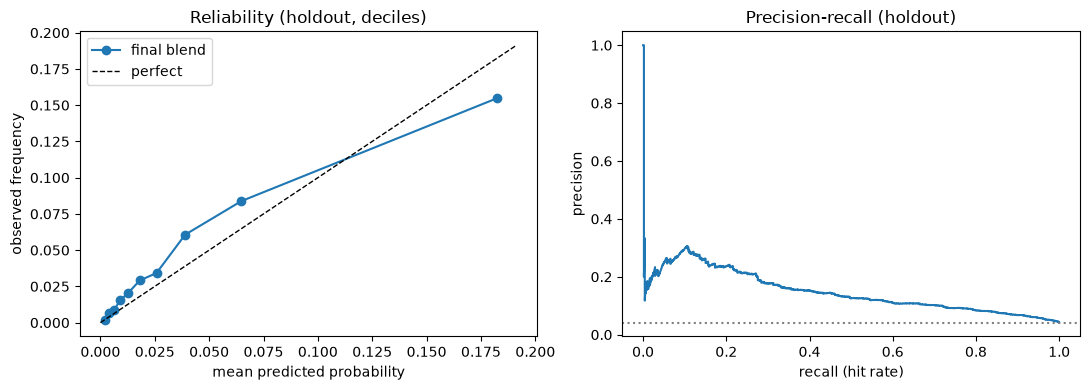

mean predicted prob 0.0364 vs holdout rate 0.0416 (drift shows up as a calibration gap)


In [18]:
pf = hold["FINAL blend"]
def ops(t):
    a = pf >= t; tp = (a & (yh == 1)).sum(); fp_ = (a & (yh == 0)).sum()
    return dict(threshold=round(t, 3), alert_rate=a.mean(), hit_rate_recall=tp / yh.sum(), false_alarm_ratio=fp_ / max(a.sum(), 1), precision=tp / max(a.sum(), 1))
display(pd.DataFrame([ops(t) for t in (THR, 0.05, 0.10, 0.20, 0.30)]).set_index("threshold"))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
qs = pd.qcut(pf, 10, duplicates="drop"); rel = pd.DataFrame(dict(p=pf, y=yh)).groupby(qs, observed=True).mean()
ax[0].plot(rel.p, rel.y, "o-", label="final blend"); m = max(rel.p.max(), rel.y.max()) * 1.05
ax[0].plot([0, m], [0, m], "k--", lw=1, label="perfect"); ax[0].set(xlabel="mean predicted probability", ylabel="observed frequency", title="Reliability (holdout, deciles)"); ax[0].legend()
Ph, Rh, _ = precision_recall_curve(yh, pf); ax[1].plot(Rh, Ph); ax[1].axhline(yh.mean(), c="gray", ls=":")
ax[1].set(xlabel="recall (hit rate)", ylabel="precision", title="Precision-recall (holdout)")
plt.tight_layout(); plt.show()
print(f"mean predicted prob {pf.mean():.4f} vs holdout rate {yh.mean():.4f} (drift shows up as a calibration gap)")

In [19]:
# Where does it fail? AP by slice (holdout rows only).
ev = pd.DataFrame(dict(y=yh, p=pf, stn=stn[vh], month=month[vh], year=yr[vh], held=HOLD["held"][vh],
                       any_missing=Gtr["missing"].values[vh].sum(1) > 0))
ev["season"] = np.where(ev.month.isin([6, 7, 8, 9]), "monsoon Jun-Sep", "other")
sl = lambda col: ev.groupby(col).apply(lambda d: pd.Series(dict(n=len(d), positives=d.y.sum(), AP=safe_ap(d.y.values, d.p.values))), include_groups=False)
for col in ["held", "season", "any_missing", "year"]: print(f"\nby {col}"); print(sl(col).round(4))
print("\nby station"); print(sl("stn").round(4).T)

# Missed events vs caught events: which standardised features differ?
Xe = fm(["weather", "physical"], Gtr)[vh]; z = (Xe - Xe.mean()) / Xe.std()
caught, missed = (pf >= THR) & (yh == 1), (pf < THR) & (yh == 1)
gap = (z[caught].mean() - z[missed].mean()).abs().sort_values(ascending=False).head(6)
print(f"\ncaught events {caught.sum()}, missed events {missed.sum()}; features that differ most (standardised mean gap):")
print(pd.DataFrame(dict(caught=z[caught].mean()[gap.index], missed=z[missed].mean()[gap.index])).round(2))


by held
            n  positives      AP
held                            
False  8772.0      398.0  0.1574
True   2924.0       88.0  0.1160

by season
                      n  positives      AP
season                                    
monsoon Jun-Sep  3904.0      272.0  0.1825
other            7792.0      214.0  0.0997

by any_missing
                   n  positives      AP
any_missing                            
False        10347.0      425.0  0.1490
True          1349.0       61.0  0.1701

by year
           n  positives      AP
year                           
2019  5840.0      239.0  0.1463
2020  5856.0      247.0  0.1529

by station
stn            ST01      ST03      ST05     ST06      ST07      ST08      ST10      ST11     ST13      ST14      ST15      ST16      ST17      ST18      ST19      ST20
n          731.0000  731.0000  731.0000  731.000  731.0000  731.0000  731.0000  731.0000  731.000  731.0000  731.0000  731.0000  731.0000  731.0000  731.0000  731.0000
positives   24.

## 9. Final fit and submission
Refit the frozen configuration on **all** of 2010-2020 (recency weights anchored at 2020), build test features, predict, write `submission.csv`. This is the first and only use of `test.csv`.

In [20]:
te = pd.read_csv(DATA / "test.csv", parse_dates=["date"]); sub = pd.read_csv(DATA / "sample_submission.csv")
tes, Gte = build_features(te)                                 # sorted by station/date; features use only past data
assert not [c for c in LEAK if c in te.columns]
print("test stations never seen in training:", sorted(set(te.station_id) - set(STATIONS)))

w_all = np.ones(len(trs)) if DECAY is None else DECAY ** (yr.max() - yr)
m = LR(C_BEST, CW)(); m.fit(fm(FS, Gtr).values, ytr, **{m.steps[-1][0] + "__sample_weight": w_all})
p_lr = m.predict_proba(fm(FS, Gte).values)[:, 1]
p_lg = np.mean([lgb.LGBMClassifier(**{**LGB_BASE, **LG_BEST}, random_state=s).fit(XLG.values, ytr, sample_weight=w_all)
                .predict_proba(fm(LGB_GROUPS, Gte).values)[:, 1] for s in SEEDS], axis=0)
p_test = np.clip(W * p_lg + (1 - W) * p_lr, 0, 1)

out = sub[["record_id"]].merge(pd.DataFrame({"record_id": tes.record_id, TARGET: p_test}), on="record_id", how="left")
assert list(out.columns) == list(sub.columns) and len(out) == len(sub) == 29200
assert out[TARGET].notna().all() and out[TARGET].between(0, 1).all() and out.record_id.is_unique
out.to_csv("submission.csv", index=False)
print(out[TARGET].describe().round(4).to_dict())
print("mean predicted probability by test year:", pd.Series(p_test).groupby(tes.date.dt.year.values).mean().round(4).to_dict(), "| train rate", round(ytr.mean(), 4))

test stations never seen in training: ['ST02', 'ST04', 'ST09', 'ST12']


{'count': 29200.0, 'mean': 0.0432, 'std': 0.0686, 'min': 0.0004, '25%': 0.0081, '50%': 0.0198, '75%': 0.0482, 'max': 0.87}
mean predicted probability by test year: {2021: 0.0423, 2022: 0.0424, 2023: 0.0428, 2024: 0.0452} | train rate 0.033


In [21]:
res = pd.DataFrame(RESULTS); res.insert(0, "run_id", range(1, len(res) + 1))
res.to_csv("experimental_results.csv", index=False)
print(len(res), "runs saved to experimental_results.csv")

44 runs saved to experimental_results.csv


## Notes and limitations
- Data are **simulated**; findings describe the simulator and the methods, not real climate.
- Unseen-station AP in one tuning fold rests on 4 stations in one year (a few dozen positives), so it is noisy: compare means and fold-consistency, not single numbers.
- Model choices were made on the tuning folds; the 2019-2020 holdout was scored once, after the configuration was frozen.
- The final fit uses all labelled years, so the submitted model is trained on more data than any scored model.